# Moran process with broadcasting - observations
In this section, I present a couple of the results that were obtained using the code from this project. A particulary interesting question is... can the absorbtion time be more than polynomial for some graph? Let's look into some simple cases first.

## Paths
When we start with one mutant, paths have a very limited number of possible states. for $n$ vertices, there is only $O(n^2)$ reachable mutant/resident state combinations. Thanks to that, we can compute wanted times and probabilities using '''exact_solver.py''', the matrix will be sufficiently small. Here are the graphs of the expected time to absorption and the probability of fixation for a Moran process with broadcasting on a path graph with at most $n=20$ vertices. Start with one mutant at the very left of the path a fitness of 1.0. The results are shown in the following figures.

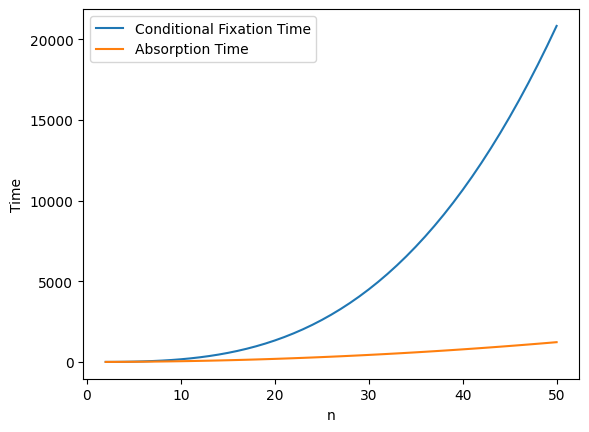

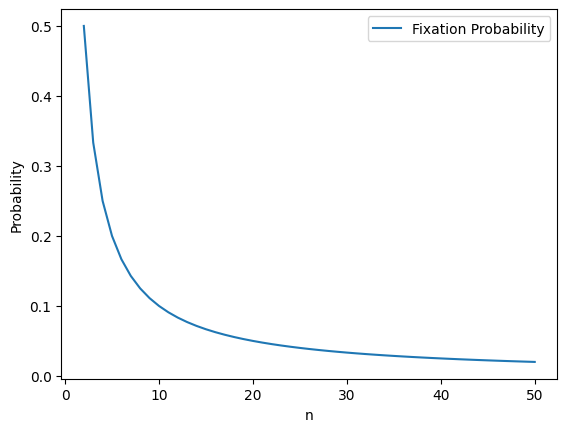

In [17]:
from moran.exact_solver import main as solve
from moran.graph_utils import *
import matplotlib.pyplot as plt

fixation_probabilities = []
conditional_fixation_times = []
absorption_times = []

for n in range(2, 21):
    #print(f"n={n}")
    edges = [str(str(i)+ " " + str(i + 1)) for i in range(n - 1)]
    graph = create_graph(edges = edges, initial_mutants = [0], normalize = True)
    results = solve(graph, mutant_fitness = 1.0)
    #print(results)
    fixation_probabilities.append(results.fixation_probability)
    conditional_fixation_times.append(results.fixation_time)
    absorption_times.append(results.absorption_time)

plt.plot(range(2, 21), conditional_fixation_times, label="Conditional Fixation Time")
plt.plot(range(2, 21), absorption_times, label="Absorption Time")
plt.xlabel("n")
plt.ylabel("Time")
plt.legend()
plt.show()

plt.plot(range(2, 21), fixation_probabilities, label="Fixation Probability")
plt.xlabel("n")
plt.ylabel("Probability")
plt.legend()
plt.show()

Now let's try mutants starting in the middle of the path. The results are shown in the following figures.

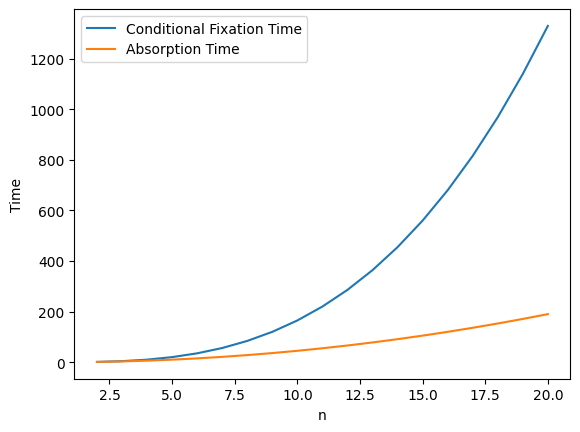

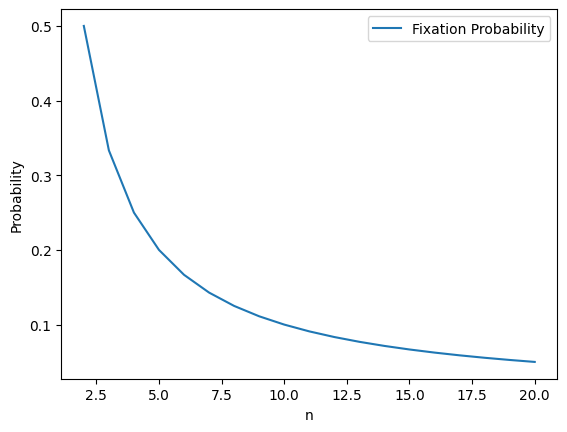

In [16]:
fixation_probabilities = []
conditional_fixation_times = []
absorption_times = []

for n in range(2, 21):
    #print(f"n={n}")
    edges = [str(str(i)+ " " + str(i + 1)) for i in range(n - 1)]
    graph = create_graph(edges = edges, initial_mutants = [0], normalize = True)
    results = solve(graph, mutant_fitness = 1.0)
    #print(results)
    fixation_probabilities.append(results.fixation_probability)
    conditional_fixation_times.append(results.fixation_time)
    absorption_times.append(results.absorption_time)

plt.plot(range(2, 21), conditional_fixation_times, label="Conditional Fixation Time")
plt.plot(range(2, 21), absorption_times, label="Absorption Time")
plt.xlabel("n")
plt.ylabel("Time")
plt.legend()
plt.show()

plt.plot(range(2, 21), fixation_probabilities, label="Fixation Probability")
plt.xlabel("n")
plt.ylabel("Probability")
plt.legend()
plt.show()

The result are fairly similar to the case of starting with one mutant at the very left of the path. In both cases, the conditional fixation time and the absorption time both "look very polynomial" in $n$.

## Star graphs
Another simple graph to look at is the star graph. However, if we give it a little thought, we can see, that the process ends very, very quickly. The reason is the center vertex. It is chosen with probability $frac{1}{n}$, where $n$ is the number of vertices in the graph. After it is chosen, it changes all of it's neighbours, thus ending the process. So the expected time to absorption is at most $O(n)$. 

We can do a little experiment here - we know the exact formula for the fixation probability of a star graph, so we can compare the results of our code with the exact formula. To make it a little more interesting, we may also change the fitness of the mutants. The results are shown in the following figure.

In [20]:
from moran.formulas import fix_prob_star_from_leaf
from moran.simulation import simulation_from_mutants as simulate

for n in range(2, 21):
    edges = [str(str(i)+ " " + str(0)) for i in range(1, n)]
    graph = create_graph(edges = edges, initial_mutants = [1], normalize = True)
    results_solve = solve(graph, mutant_fitness = 1.5)
    results_simulate = simulate(graph, mutant_fitness = 1.5, num_simulations = 10000)
    print(
        f"n={n}, fixation probability exact solver: {results_solve.fixation_probability}",
        f"fixation probability from exactformula: {fix_prob_star_from_leaf(n, 1.5)}",
        f"fixation probability from simulation: {results_simulate.fixation_probability}",
        sep="\n",
    )

n=2, fixation probability exact solver: 0.6
fixation probability from exactformula: 0.6
fixation probability from simulation: 0.6064
n=3, fixation probability exact solver: 0.47368421052631565
fixation probability from exactformula: 0.47368421052631576
fixation probability from simulation: 0.4726
n=4, fixation probability exact solver: 0.3913043478260869
fixation probability from exactformula: 0.391304347826087
fixation probability from simulation: 0.3886
n=5, fixation probability exact solver: 0.3333333333333332
fixation probability from exactformula: 0.3333333333333333
fixation probability from simulation: 0.3318
n=6, fixation probability exact solver: 0.29032258064516125
fixation probability from exactformula: 0.2903225806451613
fixation probability from simulation: 0.2881
n=7, fixation probability exact solver: 0.2571428571428571
fixation probability from exactformula: 0.2571428571428571
fixation probability from simulation: 0.2524
n=8, fixation probability exact solver: 0.23076923

As we can see, the results are very close to the exact formula. The small difference is due to the fact that we are using a Monte Carlo simulation, and thus there is some error in the results. The error can be reduced by increasing the number of simulations, but that would also increase the running time of the code.